# Gridded data
`GriddedData` holds a north-up 2d array (NaN is nodata), cell size, lower left corner and the coordinate system. The D & E parts are the start & end time of the grid.

In [1]:
import os, sys
sys.path.insert(0, os.path.abspath('..'))   # use the in-place build of the repo

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pyheclib as phl

plt.style.use('ggplot')
# restart the kernel if this is not the version / location you expect
print('pyheclib', phl.__version__, 'from', os.path.dirname(phl.__file__))

if os.path.exists('gridded_data.dss'):
    os.remove('gridded_data.dss')
dss_file = phl.open('gridded_data.dss')
dss_file

pyheclib 0.4.0 from /Users/nzahasan/Development/pyheclib/pyheclib


<DssFile open 'gridded_data.dss'>

In [2]:
ny, nx = 60, 90
yy, xx = np.mgrid[0:ny, 0:nx]
precip_grid = (20*np.exp(-((xx-45)**2 + (yy-25)**2)/300)).astype(np.float32)
precip_grid[:5, :10] = np.nan

grid = phl.GriddedData('/SHG/DEMO/PRECIP/01JAN2020:0000/01JAN2020:0100/RADAR/', precip_grid,
                       cell_size=2000.0, xll=-120000.0, yll=400000.0, unit='MM', type='PER-CUM',
                       grid_type='ALBERS', srs_name='SHG', time_zone='UTC')
dss_file.write(grid)

grid_read = dss_file.read(grid.path)
assert isinstance(grid_read, phl.GriddedData)
np.testing.assert_array_equal(np.isnan(grid_read.data), np.isnan(precip_grid))
np.testing.assert_allclose(grid_read.data, precip_grid)
assert grid_read.extent == grid.extent
grid_read.shape, grid_read.cell_size, grid_read.lower_left_cell, grid_read.start_time, grid_read.end_time

((60, 90), 2000.0, (-60, 200), '01JAN2020:0000', '01JAN2020:0100')

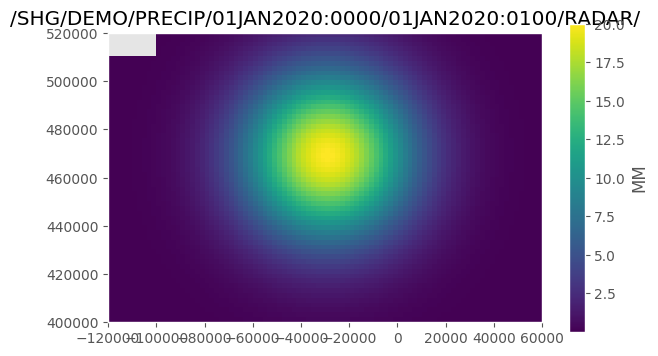

In [3]:
plt.figure(figsize=(7, 4))
plt.imshow(grid_read.data, extent=grid_read.extent, cmap='viridis')
plt.colorbar(label=grid_read.unit)
plt.grid(False)
plt.title(str(grid_read.path));

## Time invariant grid with a custom origin & nodata

In [4]:
dem = np.round(np.random.default_rng(2).normal(250, 10, (20, 30)), 1)
dem[0, :] = np.nan
dss_file.write(phl.GriddedData('/UTM/DEMO/ELEVATION///DEM/', dem, cell_size=30.0, xll=500030.0, yll=4000060.0,
                               unit='M', type='INST-VAL', origin=(500000.0, 4000000.0), nodata=-9999.0))
dem_read = dss_file.read('/UTM/DEMO/ELEVATION///DEM/')
np.testing.assert_allclose(dem_read.data, dem)
dem_read.grid_type, dem_read.lower_left_cell, dem_read.nodata, dem_read.start_time

('SPECIFIED', (1, 2), -9999.0, None)

In [5]:
dss_file.close()
print('all checks passed')

all checks passed
